# Database Design

I had a quick read of this classic paper by William Kent to get some idea of the best general practices for DB design

https://dl.acm.org/doi/pdf/10.1145/358024.358054

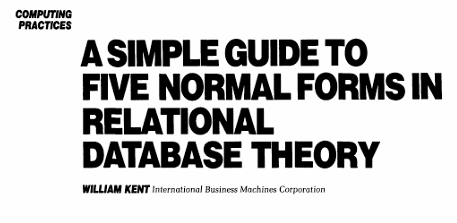


Also since I think we were all a little unclear on what fields actually correspond to what, I did some analysis using Pandas in python to get a handle on our data

In [267]:
import pandas as pd
import os

os.listdir("../../data")

['bespokeTask.txt',
 'bespokeTaskInstructions_HP.txt',
 'chrom3.txt',
 'Disease_information.txt',
 'group13',
 'group13_data',
 'group13_query_genes.csv',
 'IMPC_parameter_description.txt',
 'IMPC_procedure.txt',
 'IMPC_SOP_2026.csv',
 'lecture_10_2025.txt',
 'New Text Document.txt',
 '__MACOSX']

**Renamed genomic_annotations to genomic_transcripts**

This table will now store details about various transcripts associated with the gene


# 1. Re-organised the Genomic Annotations

(As will be discussed later, we avoided making just a `chromosome 3` table, as this wouldnt be very extendable - particularly for the bespoke task)

In [268]:
chr3 = pd.read_csv("../../data/chrom3.txt",delimiter="\t")

As we see here, there are more exons, than transcripts than genes...

In [269]:
print("number of unique gene_ids:" , len(set(chr3["Gene stable ID"])))

print("number of unique transcript_ids:",len(set(chr3["Transcript stable ID"])))

print("number of unique Exon_ids:",len(set(chr3["Exon stable ID"])))

number of unique gene_ids: 4073
number of unique transcript_ids: 14364
number of unique Exon_ids: 38328


#### **Genes to transcripts is a one to many relationship**

Each Transcript corresponds to one gene

But each gene can have many transcripts

In [270]:
print("max number of genes a transcript can have: ",chr3.groupby("Transcript stable ID")["Gene stable ID"].nunique().max())
print("max number of transcripts a gene can have: ",chr3.groupby("Gene stable ID")["Transcript stable ID"].nunique().max())

max number of genes a transcript can have:  1
max number of transcripts a gene can have:  244


#### **Transcripts to Exons is a many to many relationship**

Each Transcript corresponds has many Exons 

But each Exon can be part of many distinct Transcripts

**Hence, a joining table is appropriate to represent this**

In [271]:
print("max number of Exons a transcript can have: ",chr3.groupby("Transcript stable ID")["Exon stable ID"].nunique().max())
print("max number of transcripts a Exon can have (be a part of): ",chr3.groupby("Exon stable ID")["Transcript stable ID"].nunique().max())


max number of Exons a transcript can have:  86
max number of transcripts a Exon can have (be a part of):  150


Each exon has ONLY one exon start and one end

But each transcript has many exon start and ends

**Therefore, as the Exon Start and End only tell you about the specific exon, we should put these in the exon table**

...as per the third normal form in relational database theory (Kent, 1983)

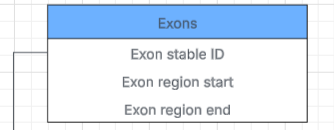

In [272]:
print("max number of start positions an exon can have:",chr3.groupby("Exon stable ID")["Exon region start (bp)"].nunique().max())
print("max number of end positions an exon can have:",chr3.groupby("Exon stable ID")["Exon region end (bp)"].nunique().max())
print()
print("As you may expect, each transcript can have many exon start positions:", chr3.groupby("Transcript stable ID")["Exon region start (bp)"].nunique().max())

max number of start positions an exon can have: 1
max number of end positions an exon can have: 1

As you may expect, each transcript can have many exon start positions: 86


**Exon rank in transcript describes BOTH an EXON and a TRANSCRIPT therefore it belongs in the joining table.**

Because a transcript has many exons its part of, and an exon can have many transcripts it's part of

...as per the second normal form in relational database theory (Kent, 1983)

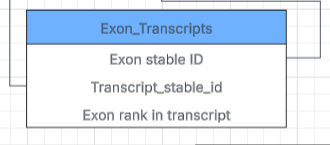

In [273]:
print("max number of Exon ranks a transcript can have:", chr3.groupby("Transcript stable ID")["Exon rank in transcript"].nunique().max())
print("max number of Exon ranks an exon can have:", chr3.groupby("Exon stable ID")["Exon rank in transcript"].nunique().max())

max number of Exon ranks a transcript can have: 86
max number of Exon ranks an exon can have: 9


**By process of elimination, and because one transcript always belongs to one gene, these are the fields in the transcripts table**

This is a slightly sparse table, it would be typical to have something like `transcript name` in there, but we've not been given this...


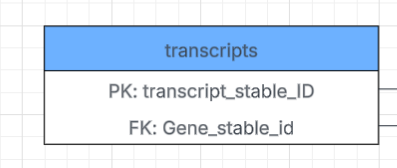

But this design eliminates redundancy, and is actually similar to that which is used by ENSEMBL

https://jun2026.archive.ensembl.org/info/docs/api/core/diagrams/Core.fundamental_tables.svg

---

# 2. Re-organised the Human Disease Genes

In [274]:
disease = pd.read_csv("../../data/Disease_information.txt",delimiter="\t", skiprows=18,header=None)
cols = ["Human Gene Symbol","Human Gene Name","HGNC ID for human gene","DO term name associated with human gene","DO term ID associated with human gene","Mouse genotype IDs associated with DO term","Mouse Gene","MGI Mouse Gene ID"]
disease.columns = cols

**Genes can be associated with many Diseases**

**Diseases can be associated with many Genes**

It is a many to many relationship, therefore it is a good idea to use a joining table here. 

In [295]:
print("Max number of diseases a GENE can be associated with: ",disease.groupby("HGNC ID for human gene")["DO term ID associated with human gene"].nunique().max())
print("Max number of genes a disease can be associated with: ",disease.groupby("DO term ID associated with human gene")["Human Gene Symbol"].nunique().max())

Max number of diseases a GENE can be associated with:  87
Max number of genes a disease can be associated with:  173


This table only contains genes where there is a 1:1 relationship between humans and mice

For this, we don't need to worry about possible many-to-many relationships. BUT for our bespoke task, we will need to make an orthologs table (see next section)

For this reason, the Mouse and Human genes are connected via the ortholog table, which is connected to the disease genes table. 
- This removes the need to store human_gene_id and mouse_gene_id in the disease genes joining table, and it comes with benefits for the following bespoke task. 
- This prevents us from adding human disease genes with no corresponding mouse gene, but this wouldnt make sense given we're trying to look at relationships between humans and mouse models
- The design still depends on there being 1:1 orthology between human and mouse disease genes because we'd have a lot of duplication if we began adding non-1:1 genes (i.e., for genes with 1 human copy and many mouse copies).

- Looking up human disease genes needs one join through the orthologs table. If this became a bottleneck, an index or view would be the first step. Copying gene IDs into the disease-genes table would speed queries further but risks inconsistency.


- So in future, it is possible that adding human_gene_id and mouse_gene_id to the disease_genes table (alongside ortholog_id) could improve query speed. But as this would be relatively easy to implement, and isnt necessary for our current data, I've ommited this.

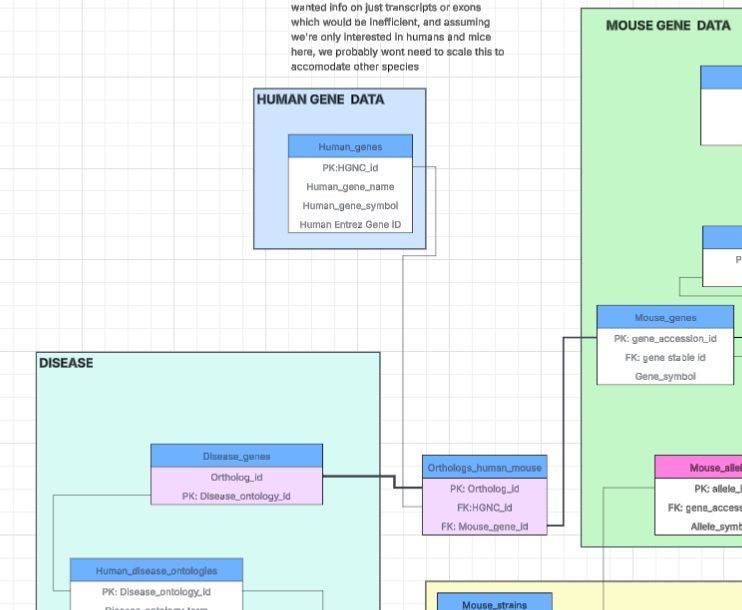

In [294]:
print("Max number of diseases a GENE can be associated with: ",disease.groupby("HGNC ID for human gene")["MGI Mouse Gene ID"].nunique().max())
print("Max number of genes a disease can be associated with: ",disease.groupby("MGI Mouse Gene ID")["HGNC ID for human gene"].nunique().max())

Max number of diseases a GENE can be associated with:  1
Max number of genes a disease can be associated with:  1


**I made a table specifically for holding the different mouse genotypes, and the human disease ontology term IDs that they represent**

This is to ensure the atomicity of the database (first normal form of relational databases)

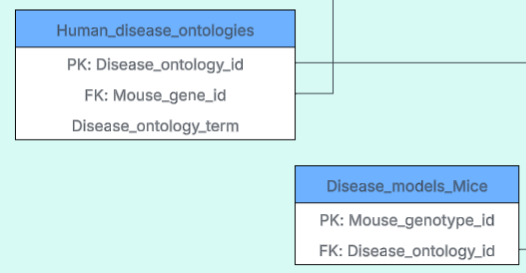

# 3. Incorporating the bespoke task data into our DB



> The task requires us to accomodate many more genes from other chromosomes (e.g., one of the genes in the bespoke task table, Gm13102 [MGI:3703005] which is located on mouse chromosome 4) 


- We have also been told that the DB will likely need data from other chromosomes too. Luckily this is no problem with the design I already implemented

- We also need to accomodate data on the phenotypes
- We also should expect that more data fields such as `Human phenotype name` and `Human phenotype description` will be added in the future. As such we need to make the DB flexible too
 

In [276]:
# Loading in the human phenotype DF
hp_dat = pd.read_csv("../../data/bespokeTask.txt",delimiter="\t",header=None)
hp_dat.columns = ["Human Marker Symbol","Human Entrez Gene ID", "Mouse Marker Symbol","MGI Marker Accession ID","High-level Mammalian Phenotype ID",""]
hp_dat.drop("",axis=1,inplace=True)

**We can add entrez IDs directly to our human_genes table using the HUGO symbols since these already map 1:1**

In [314]:
display(hp_dat[["Human Entrez Gene ID","Human Marker Symbol"]].head())

print(hp_dat.groupby("Human Entrez Gene ID")["Human Marker Symbol"].nunique().max())
print(hp_dat.groupby("Human Marker Symbol")["Human Entrez Gene ID"].nunique().max())

,Human Entrez Gene ID,Human Marker Symbol
0,1,A1BG
1,29974,A1CF
2,2,A2M
3,127550,A3GALT2
4,53947,A4GALT


1
1


Same goes for the mouse_genes and the MGI_ids

In [326]:
display(hp_dat[["Mouse Marker Symbol","MGI Marker Accession ID"]].head())

print(hp_dat.groupby("Mouse Marker Symbol")["MGI Marker Accession ID"].nunique().max())
print(hp_dat.groupby("MGI Marker Accession ID")["Mouse Marker Symbol"].nunique().max())

,Mouse Marker Symbol,MGI Marker Accession ID
0,A1bg,MGI:2152878
1,A1cf,MGI:1917115
2,A2m,MGI:2449119
3,A3galt2,MGI:2685279
4,A4galt,MGI:3512453


1
1


Here we can see that there are orthologous relationships between the human and mouse genes 

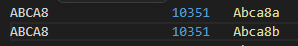

Luckily, with our orthologs table, these are handled well, reducing redundancy

**Finally, we add the high-level mammalian phenotypes.**

As with the genotypes before, we have to break these up into atomised data (first normal form of relational databases) 

In [331]:
hp_dat[["High-level Mammalian Phenotype ID"]].head()

,High-level Mammalian Phenotype ID
0,...
1,"MP:0005367, MP:0005369, MP:0005370, MP:000537..."
2,...
3,...
4,"MP:0005376, MP:0005386, MP:0010768 ..."


For this I made the 